In [2]:
print("Sentiment Intelligence System")
print("Python environment is working!")

Sentiment Intelligence System
Python environment is working!


In [3]:
import pandas as pd

url = "hf://datasets/Madnesss/amazon-beauty-analytics-ready/reviews"

df = pd.read_parquet(
    url,
    filters=[("split", "=", "train")],
    columns=["text_full", "sentiment", "rating"]
)

df = df.groupby("sentiment", group_keys=False).sample(
    n=5000,
    random_state=42
)

df.head()

c:\Users\Rachitesh Sharma\Documents\sentiment-intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,text_full,sentiment,rating
1511214,Good looking cut for low price if you're a tub...,negative,2.0
1802414,"NOT ""100% UVA and UVB Protection"". Posted as ""...",negative,1.0
280334,what I received was not what is advertised I k...,negative,2.0
1210746,Two Stars. color change fast turned white.,negative,2.0
1334248,Now my feet and HEAD hurt!. This thing is so l...,negative,1.0


In [4]:
df.shape


(15000, 3)

In [5]:
df["sentiment"].value_counts()

sentiment
negative    5000
neutral     5000
positive    5000
Name: count, dtype: int64

In [6]:
df.info()


<class 'pandas.DataFrame'>
Index: 15000 entries, 1511214 to 1995843
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   text_full  15000 non-null  str    
 1   sentiment  15000 non-null  str    
 2   rating     15000 non-null  float64
dtypes: float64(1), str(2)
memory usage: 3.4 MB


In [7]:
df[["text_full", "sentiment", "rating"]].sample(5, random_state=42)

,text_full,sentiment,rating
1242199,And I love it. I have a nice even tan from ......,positive,5.0
282401,ORDER A SIZE BIGGER. NEED TO ORDER A SIZE BIGG...,neutral,3.0
1600029,"Different,Cute and Big. I bought this for a ho...",positive,5.0
927104,Had great potential but not sure what went wro...,negative,2.0
181515,Wanted to love it. Been looking for a less exp...,neutral,3.0


In [8]:
df.groupby("sentiment")["rating"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
sentiment,,,,
negative,5000,1.3634,1.0,2.0
neutral,5000,3.0000,3.0,3.0
positive,5000,4.8002,4.0,5.0


In [9]:
df["text_full"].duplicated().sum()


np.int64(1)

In [10]:
df=df.drop_duplicates(subset=["text_full"]).copy()
print(df.shape)

(14999, 3)


In [11]:
df["text_full"].str.len().describe()

count    14999.000000
mean       197.992199
std        249.686807
min         15.000000
25%         70.000000
50%        135.000000
75%        242.000000
max      11352.000000
Name: text_full, dtype: float64

In [12]:
df.loc[df["text_full"].str.len().idxmax(), "text_full"]

"Everything You Want to Know about Skincare Products. There are many things that unspecialized people must be aware of before purchasing and/or using any chemical or even herbal products. Anti aging cream products spread all over the market and many people are not aware of the ingredients, how they work, what are the qualities of a good anti aging cream product, and what are the side effects that such products may pose. You probably know the benefits of Vitamin C serum, but what about the hidden side of it? We know that vitamin C serum a) Acts as an antioxidant, b) Helps produce collagen, c) Restores skin damage. But the other side is often not highlighted from manufacturers. So, to unravel some of the mysteries about skin care products, I would listen to what the experts say about a given product and read scientific conclusions of the effects so that you know what you are doing to your body, skin, etc. In this review, I chose an article from Felicia Rose Labs web that demonstrates the

In [13]:
df.loc[df["text_full"].str.len().idxmin(), "text_full"]

'Lobe. I love it'

In [14]:
df["text_full"].str.lower().str.split().explode().value_counts().head(20)

text_full
the     25692
i       18735
and     15158
a       14063
it      12832
to      11484
is       8408
for      7609
not      7275
but      7083
of       6484
this     6463
my       6265
was      5381
in       5199
very     4070
on       4064
they     3859
are      3669
that     3577
Name: count, dtype: int64

In [15]:
unique_words = df["text_full"].str.lower().str.split().explode().nunique()
unique_words

32649

In [16]:
df["clean_text"] = df["text_full"].str.lower()

df[["text_full", "clean_text"]].head()

,text_full,clean_text
1511214,Good looking cut for low price if you're a tub...,good looking cut for low price if you're a tub...
1802414,"NOT ""100% UVA and UVB Protection"". Posted as ""...","not ""100% uva and uvb protection"". posted as ""..."
280334,what I received was not what is advertised I k...,what i received was not what is advertised i k...
1210746,Two Stars. color change fast turned white.,two stars. color change fast turned white.
1334248,Now my feet and HEAD hurt!. This thing is so l...,now my feet and head hurt!. this thing is so l...


In [17]:
df["clean_text"].str.contains(r"<[^>]+>", regex=True).sum()

np.int64(0)

In [18]:
import re
import string

df["clean_text"].str.count(
    f"[{re.escape(string.punctuation)}]"
).sum()

np.int64(100869)

In [19]:
df["clean_text"].str.contains(
    r"https?://\S+|www\.\S+",
    regex=True
).sum()

np.int64(6)

In [20]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()
df["clean_text"] = df["text_full"].apply(preprocess_text)
df[["text_full", "clean_text"]].sample(5, random_state=42)

,text_full,clean_text
2264557,came in late. cute but bigger than it thought ...,came in late. cute but bigger than it thought ...
248073,Works for awhile. It works. But doesn’t last l...,works for awhile. it works. but doesn’t last l...
588483,Didn't wear but a few hour and the gold chain ...,didn't wear but a few hour and the gold chain ...
927104,Had great potential but not sure what went wro...,had great potential but not sure what went wro...
324615,Beautiful design but be carefull with the size...,beautiful design but be carefull with the size...


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X = vectorizer.fit_transform(df["clean_text"])

print("Shape:", X.shape)

Shape: (14999, 10000)


In [22]:
from sklearn.model_selection import train_test_split
y=df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (11999, 10000)
Test set shape: (3000, 10000)


In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


In [24]:
y_pred = model.predict(X_test)
print("Predictions are:", y_pred[:10])

Predictions are: ['neutral' 'neutral' 'negative' 'positive' 'positive' 'negative' 'neutral'
 'positive' 'neutral' 'negative']


In [25]:
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7596666666666667


In [26]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.74      0.76      0.75      1000
     neutral       0.67      0.69      0.68      1000
    positive       0.88      0.83      0.85      1000

    accuracy                           0.76      3000
   macro avg       0.76      0.76      0.76      3000
weighted avg       0.76      0.76      0.76      3000



In [27]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[756 216  28]
 [221 688  91]
 [ 46 119 835]]


In [28]:
from sklearn.svm import LinearSVC

model_svm = LinearSVC(
    max_iter=1000,
    random_state=42
)
model_svm.fit(X_train, y_train)
print("SVM Model training completed.")

SVM Model training completed.


In [29]:
y_pred = model_svm.predict(X_test)
print("SVM Model predictions completed.", y_pred[:10])

SVM Model predictions completed. ['neutral' 'neutral' 'negative' 'positive' 'negative' 'negative' 'neutral'
 'positive' 'neutral' 'negative']


In [30]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("SVM Model Accuracy:", accuracy)
print("SVM Model Classification Report:\n", report)
print("SVM Model Confusion Matrix:\n", cm)


SVM Model Accuracy: 0.741
SVM Model Classification Report:
               precision    recall  f1-score   support

    negative       0.74      0.75      0.74      1000
     neutral       0.65      0.64      0.65      1000
    positive       0.83      0.83      0.83      1000

    accuracy                           0.74      3000
   macro avg       0.74      0.74      0.74      3000
weighted avg       0.74      0.74      0.74      3000

SVM Model Confusion Matrix:
 [[748 216  36]
 [228 642 130]
 [ 41 126 833]]


In [31]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=1000,
    random_state=42
)
model_rf.fit(X_train, y_train)
print("Random Forest Model training completed.")

Random Forest Model training completed.


In [32]:
y_pred = model_rf.predict(X_test)
print("Random Forest Model predictions completed.", y_pred[:10])

Random Forest Model predictions completed. ['neutral' 'neutral' 'negative' 'positive' 'neutral' 'neutral' 'positive'
 'positive' 'neutral' 'negative']


In [33]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Random Forest Model Accuracy:", accuracy)
print("Random Forest Model Classification Report:\n", report)
print("Random Forest Model Confusion Matrix:\n", cm)


Random Forest Model Accuracy: 0.7493333333333333
Random Forest Model Classification Report:
               precision    recall  f1-score   support

    negative       0.74      0.77      0.76      1000
     neutral       0.67      0.67      0.67      1000
    positive       0.84      0.81      0.82      1000

    accuracy                           0.75      3000
   macro avg       0.75      0.75      0.75      3000
weighted avg       0.75      0.75      0.75      3000

Random Forest Model Confusion Matrix:
 [[767 190  43]
 [217 668 115]
 [ 46 141 813]]


## Corrected ML Pipeline — Preventing Data Leakage


In [34]:
from sklearn.model_selection import train_test_split
x_text_train = df["clean_text"]
y = df["sentiment"]

x_text_train, x_text_test, y_train, y_test = train_test_split(
    x_text_train, y, test_size=0.2, random_state=42, stratify=y
)
print("Training Sample Size:", len(x_text_train))
print("Testing Sample Size:", len(x_text_test))

Training Sample Size: 11999
Testing Sample Size: 3000


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer_final = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)
X_train_final = vectorizer_final.fit_transform(x_text_train)
print("Final TF-IDF Vectorization completed. Shape:", X_train_final.shape)
    

Final TF-IDF Vectorization completed. Shape: (11999, 10000)


In [36]:
X_test_final = vectorizer_final.transform(x_text_test)
print("Final TF-IDF Transformation for test data completed. Shape:", x_test_final.shape)

NameError: name 'x_test_final' is not defined

In [37]:
from sklearn.linear_model import LogisticRegression
lrmodel_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lrmodel_final.fit(X_train_final, y_train)
print("Final Logistic Regression Model training completed.")

Final Logistic Regression Model training completed.


In [38]:
y_final_pred = lrmodel_final.predict(X_test_final)
print("Final Logistic Regression Model predictions completed.", y_final_pred[:10])

Final Logistic Regression Model predictions completed. ['neutral' 'neutral' 'negative' 'positive' 'positive' 'negative' 'neutral'
 'positive' 'neutral' 'negative']


In [39]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_final_pred)
report = classification_report(y_test, y_final_pred)
cm = confusion_matrix(y_test, y_final_pred)

print("Final Logistic Regression Model Accuracy:", accuracy)
print("Final Logistic Regression Model Classification Report:\n", report)  
print("Final Logistic Regression Model Confusion Matrix:\n", cm)

Final Logistic Regression Model Accuracy: 0.7606666666666667
Final Logistic Regression Model Classification Report:
               precision    recall  f1-score   support

    negative       0.74      0.75      0.75      1000
     neutral       0.67      0.69      0.68      1000
    positive       0.87      0.84      0.85      1000

    accuracy                           0.76      3000
   macro avg       0.76      0.76      0.76      3000
weighted avg       0.76      0.76      0.76      3000

Final Logistic Regression Model Confusion Matrix:
 [[753 219  28]
 [214 691  95]
 [ 45 117 838]]


In [40]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()
sample_review = df["clean_text"].iloc[0]
scores = analyzer.polarity_scores(sample_review)
print("Sample Review:", sample_review)
print("VADER Sentiment Scores for Sample Review:", scores)


Sample Review: good looking cut for low price if you're a tubercular thin chinese waiter. the waist & chest are not american proportioned to one another unless you have no problem slipping into your skinny jeans. the sizes are definitely chinese : an extra large was tight where i normally fit a large just right. which is a shame because the styling for the very low price is a bargain.
VADER Sentiment Scores for Sample Review: {'neg': 0.12, 'neu': 0.73, 'pos': 0.15, 'compound': 0.3538}


In [41]:
def vader_sentiment(compound):
    if compound >= 0.05:
        return "positive"
    elif compound <= -0.05:
        return "negative"
    else:
        return "neutral"

def get_vader_sentiment(text):
    scores = analyzer.polarity_scores(text)['compound']
    return vader_sentiment(scores)

df["vader_sentiment"] = df["clean_text"].apply(get_vader_sentiment)
print(df["vader_sentiment"].value_counts())
    

vader_sentiment
positive    9822
negative    3591
neutral     1586
Name: count, dtype: int64


In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
vader_accuracy = accuracy_score(df["sentiment"], df["vader_sentiment"])
vader_report = classification_report(df["sentiment"], df["vader_sentiment"])
vader_cm = confusion_matrix(df["sentiment"], df["vader_sentiment"])
print("VADER Sentiment Analysis Accuracy:", vader_accuracy)
print("Classification Report:", vader_report)
print("Confusion Matrix:", vader_cm)

VADER Sentiment Analysis Accuracy: 0.5200346689779318
Classification Report:               precision    recall  f1-score   support

    negative       0.69      0.50      0.58      5000
     neutral       0.40      0.13      0.19      5000
    positive       0.48      0.94      0.63      4999

    accuracy                           0.52     14999
   macro avg       0.52      0.52      0.47     14999
weighted avg       0.52      0.52      0.47     14999

Confusion Matrix: [[2486  757 1757]
 [ 995  627 3378]
 [ 110  202 4687]]


In [43]:
from sklearn.model_selection import train_test_split

X_text = df["clean_text"]
y = df["sentiment"]

X_text_train, X_text_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_text_train))
print("Testing samples:", len(X_text_test))

Training samples: 11999
Testing samples: 3000


In [44]:
test_vader_sentiment = X_text_test.apply(get_vader_sentiment)
print("VADER Sentiment Analysis on Test Data completed. Sample predictions:", test_vader_sentiment[:10])

VADER Sentiment Analysis on Test Data completed. Sample predictions: 1375212    positive
293097     positive
637733     negative
661931     positive
503680     positive
257518     negative
2279243    positive
2299458    positive
438387     negative
1030354    negative
Name: clean_text, dtype: str


In [45]:
 vadar_accuracy_test = accuracy_score(y_test, test_vader_sentiment)
 vadar_report_test = classification_report(y_test, test_vader_sentiment)
 vadar_cm_test = confusion_matrix(y_test, test_vader_sentiment)

 print("VADER Sentiment Analysis on Test Data Accuracy:", vadar_accuracy_test)
 print("Classification Report:\n", vadar_report_test)
 print("Confusion Matrix:\n", vadar_cm_test)

VADER Sentiment Analysis on Test Data Accuracy: 0.5323333333333333
Classification Report:
               precision    recall  f1-score   support

    negative       0.69      0.52      0.59      1000
     neutral       0.42      0.14      0.20      1000
    positive       0.49      0.94      0.65      1000

    accuracy                           0.53      3000
   macro avg       0.53      0.53      0.48      3000
weighted avg       0.53      0.53      0.48      3000

Confusion Matrix:
 [[517 149 334]
 [217 135 648]
 [ 20  35 945]]


In [46]:
def get_vader_scores(text):
    return analyzer.polarity_scores(text)
vader_scores = df["clean_text"].apply(get_vader_scores)
print("VADER Sentiment Scores for all reviews computed. Sample scores:", vader_scores.head())

VADER Sentiment Scores for all reviews computed. Sample scores: 1511214    {'neg': 0.12, 'neu': 0.73, 'pos': 0.15, 'compo...
1802414    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
280334     {'neg': 0.101, 'neu': 0.899, 'pos': 0.0, 'comp...
1210746    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
1334248    {'neg': 0.119, 'neu': 0.881, 'pos': 0.0, 'comp...
Name: clean_text, dtype: object


In [47]:
vadar_features = pd.DataFrame(vader_scores.tolist())
vadar_features.head()

,neg,neu,pos,compound
0,0.120,0.730,0.15,0.3538
1,0.000,1.000,0.00,0.0000
2,0.101,0.899,0.00,-0.4445
3,0.000,1.000,0.00,0.0000
4,0.119,0.881,0.00,-0.7644


In [48]:
print(vadar_features.shape)

(14999, 4)


In [49]:
vader_features = pd.DataFrame(vader_scores.tolist(), index=df.index)

print(vader_features.shape)

(14999, 4)


In [ ]:
print("VADER index type:", type(vader_features.index))
print("Train index type:", type(X_text_train.index))
print("Test index type:", type(X_text_test.index))

VADER index type: <class 'pandas.Index'>
Train index type: <class 'pandas.Index'>
Test index type: <class 'pandas.Index'>


In [ ]:
print("First VADER indexes:", vader_features.index[:5].tolist())
print("First train indexes:", X_text_train.index[:5].tolist())
print("First test indexes:", X_text_test.index[:5].tolist())

First VADER indexes: [1511214, 1802414, 280334, 1210746, 1334248]
First train indexes: [391303, 957225, 556379, 2192798, 775732]
First test indexes: [1375212, 293097, 637733, 661931, 503680]


In [ ]:
vader_train = vader_features.reindex(X_text_train.index)
vader_test = vader_features.reindex(X_text_test.index)

print("VADER training shape:", vader_train.shape)
print("VADER testing shape:", vader_test.shape)

VADER training shape: (11999, 4)
VADER testing shape: (3000, 4)


In [ ]:
from scipy.sparse import hstack

X_train_hybrid = hstack([X_train_final, vader_train])
X_test_hybrid = hstack([X_test_final, vader_test])

print("Training hybrid shape:", X_train_hybrid.shape)
print("Testing hybrid shape:", X_test_hybrid.shape)

Training hybrid shape: (11999, 20004)
Testing hybrid shape: (3000, 20004)


In [ ]:
hybrid_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
hybrid_model.fit(X_train_hybrid, y_train)
print("Hybrid Model training completed.")

Hybrid Model training completed.


In [ ]:
y_hybrid_pred = hybrid_model.predict(X_test_hybrid)
print("Hybrid Model predictions completed. Sample predictions:", y_hybrid_pred[:10])

Hybrid Model predictions completed. Sample predictions: ['neutral' 'neutral' 'negative' 'positive' 'positive' 'negative' 'neutral'
 'positive' 'neutral' 'negative']


In [ ]:
print("Hybrid model exists:", "hybrid_model" in globals())
print("Hybrid test data exists:", "X_test_hybrid" in globals())

Hybrid model exists: True
Hybrid test data exists: True


In [ ]:
from sklearn.metrics import accuracy_score
accuracy_hybrid = accuracy_score(y_test, y_hybrid_pred)
print("Hybrid Model Accuracy:", accuracy_hybrid * 100, "%")

Hybrid Model Accuracy: 76.2 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
classification_report_hybrid = classification_report(y_test, y_hybrid_pred)
confusion_matrix_hybrid = confusion_matrix(y_test, y_hybrid_pred)   

print("Hybrid Model Classification Report:\n", classification_report_hybrid)
print("Hybrid Model Confusion Matrix:\n", confusion_matrix_hybrid)

Hybrid Model Classification Report:
               precision    recall  f1-score   support

    negative       0.75      0.77      0.76      1000
     neutral       0.68      0.67      0.67      1000
    positive       0.86      0.85      0.85      1000

    accuracy                           0.76      3000
   macro avg       0.76      0.76      0.76      3000
weighted avg       0.76      0.76      0.76      3000

Hybrid Model Confusion Matrix:
 [[767 207  26]
 [218 667 115]
 [ 36 112 852]]


In [ ]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

c:\Users\Rachitesh Sharma\Documents\sentiment-intelligence\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Rachitesh Sharma\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [ ]:
sample_tokens = tokenizer("This product is absolutely amazing!")

print(sample_tokens)

{'input_ids': [101, 2023, 4031, 2003, 7078, 6429, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
from transformers import AutoModelForSequenceClassification
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=3)

c:\Users\Rachitesh Sharma\Documents\sentiment-intelligence\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Rachitesh Sharma\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2310.47it/s]
[transformers] DistilBertForSeque

In [ ]:
label_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

y_train_numeric = y_train.map(label_map)
y_test_numeric = y_test.map(label_map)

print(y_train_numeric.value_counts())
print(y_test_numeric.value_counts())

sentiment
1    4000
0    4000
2    3999
Name: count, dtype: int64
sentiment
1    1000
0    1000
2    1000
Name: count, dtype: int64


In [ ]:
train_tokens = tokenizer(
    X_text_train.tolist(),
    padding=True,
    truncation=True,
    max_length=128
)

print("Tokenization completed. Sample tokens:", train_tokens["input_ids"][:5])


Tokenization completed. Sample tokens: [[101, 2093, 3340, 1012, 2009, 1005, 1055, 7929, 2005, 1996, 3976, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [101, 2200, 2092, 2881, 1998, 2081, 1012, 1012, 1996, 2564, 2038, 2018, 2028, 2005, 2086, 1998, 7459, 2009, 2016, 2787, 2000, 5587, 2256, 4587, 2684, 2000, 1996, 2862, 1012, 100, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [101, 2274, 3340, 1012, 2004, 2574, 2004, 1045, 2288, 1996, 3

In [ ]:
from datasets import Dataset

train_dataset = Dataset.from_dict({
    "text": X_text_train.tolist(),
    "label": y_train_numeric.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_text_test.tolist(),
    "label": y_test_numeric.tolist()
})

print("Training dataset:", train_dataset)
print("Testing dataset:", test_dataset)

Training dataset: Dataset({
    features: ['text', 'label'],
    num_rows: 11999
})
Testing dataset: Dataset({
    features: ['text', 'label'],
    num_rows: 3000
})


In [ ]:
def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [ ]:
train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True) 

print("Tokenization of datasets completed. Sample training dataset:", train_dataset[0])
print("Sample testing dataset:", test_dataset[0])

Map: 100%|██████████| 3000/3000 [00:00<00:00, 11958.66 examples/s]

Tokenization of datasets completed. Sample training dataset: {'text': "three stars. it's ok for the price.", 'label': 1, 'input_ids': [101, 2093, 3340, 1012, 2009, 1005, 1055, 7929, 2005, 1996, 3976, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1,

In [ ]:
train_dataset = train_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

print(train_dataset.column_names)
print(test_dataset.column_names)

['label', 'input_ids', 'token_type_ids', 'attention_mask']
['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    report_to="none"
)

print("Training configuration created.")

Training configuration created.


In [ ]:
from transformers import Trainer
trainer = Trainer(
    model=model,   
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)
print("Trainer created successfully.")

Trainer created successfully.


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

CUDA available: False
Running on CPU


In [ ]:
train_small = train_dataset.filter(
    lambda x: x["label"] in [0, 1, 2]
).shuffle(seed=42).select(range(1500))

print("Small training dataset:", train_small)

Filter: 100%|██████████| 11999/11999 [00:00<00:00, 68634.37 examples/s]

Small training dataset: Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1500
})


In [ ]:
from collections import Counter

print(Counter(train_small["label"]))

Counter({2: 503, 1: 503, 0: 494})


In [ ]:
train_small = train_small.filter(
    lambda x: x["label"] in [0, 1, 2]
)

train_small = train_small.shuffle(seed=42)

class_0 = train_small.filter(lambda x: x["label"] == 0).select(range(494))
class_1 = train_small.filter(lambda x: x["label"] == 1).select(range(494))
class_2 = train_small.filter(lambda x: x["label"] == 2).select(range(494))

train_small = concatenate_datasets([class_0, class_1, class_2]).shuffle(seed=42)

print(train_small)
print(Counter(train_small["label"]))

Filter: 100%|██████████| 1500/1500 [00:00<00:00, 35527.89 examples/s]


NameError: name 'concatenate_datasets' is not defined

In [ ]:
from datasets import concatenate_datasets

train_small = concatenate_datasets(
    [class_0, class_1, class_2]
).shuffle(seed=42)

print(train_small)
print(Counter(train_small["label"]))

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1482
})
Counter({0: 494, 2: 494, 1: 494})


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_small,
    eval_dataset=test_dataset
)

print("Trainer updated with the smaller training dataset.")

Trainer updated with the smaller training dataset.


In [ ]:
training_args = TrainingArguments(
    output_dir="./distilbert_results",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none"
)

print("CPU-friendly training configuration created.")

CPU-friendly training configuration created.


In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3
)

print("Fresh DistilBERT model loaded.")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 616.10it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model loaded.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_small,
    eval_dataset=test_dataset
)

print("Trainer ready.")

Trainer ready.


In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.752511,0.671006


TrainOutput(global_step=186, training_loss=0.8423570279152163, metrics={'train_runtime': 562.2221, 'train_samples_per_second': 2.636, 'train_steps_per_second': 0.331, 'total_flos': 49080046459392.0, 'train_loss': 0.8423570279152163, 'epoch': 1.0})

In [ ]:
results = trainer.evaluate()

print(results)

Training Loss,Validation Loss,Epoch
0.752511,0.671006,1


{'eval_loss': 0.6710059642791748}


In [ ]:
predictions = trainer.predict(test_dataset)

print(predictions.metrics)

{'test_loss': 0.6710059642791748, 'test_runtime': 177.7012, 'test_samples_per_second': 16.882, 'test_steps_per_second': 2.11}


In [ ]:
import numpy as np

pred_labels = np.argmax(predictions.predictions, axis=1)

print("Predictions generated:", len(pred_labels))
print("First 10 predictions:", pred_labels[:10])

Predictions generated: 3000
First 10 predictions: [1 1 0 1 1 0 2 2 0 0]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(y_test_numeric, pred_labels))

print("\nClassification Report:")
print(
    classification_report(
        y_test_numeric,
        pred_labels,
        target_names=["negative", "neutral", "positive"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_numeric, pred_labels))

Accuracy: 0.708

Classification Report:
              precision    recall  f1-score   support

    negative       0.69      0.76      0.72      1000
     neutral       0.63      0.48      0.55      1000
    positive       0.78      0.88      0.83      1000

    accuracy                           0.71      3000
   macro avg       0.70      0.71      0.70      3000
weighted avg       0.70      0.71      0.70      3000


Confusion Matrix:
[[764 188  48]
 [318 483 199]
 [ 28  95 877]]


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "TF-IDF + VADER + Logistic Regression",
        "DistilBERT"
    ],
    "Accuracy": [
        0.7607,
        0.7620,
        0.7080
    ],
    "Macro F1": [
        0.76,
        0.76,
        0.70
    ]
})

model_comparison

,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.7607,0.76
1,TF-IDF + VADER + Logistic Regression,0.7620,0.76
2,DistilBERT,0.7080,0.70


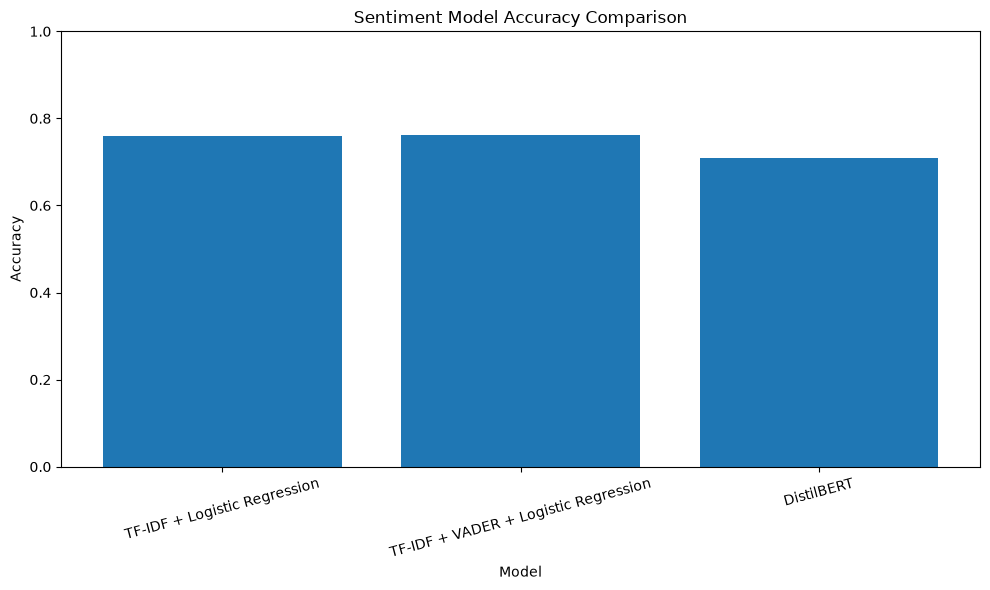

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"]
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Sentiment Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [ ]:
sentiment_counts = df["sentiment"].value_counts()

print(sentiment_counts)

print("\nPercentages:")
print((sentiment_counts / len(df) * 100).round(2))

sentiment
negative    5000
neutral     5000
positive    4999
Name: count, dtype: int64

Percentages:
sentiment
negative    33.34
neutral     33.34
positive    33.33
Name: count, dtype: float64


In [50]:
rating_by_sentiment = df.groupby("sentiment")["rating"].agg(["count", "mean","median", "min", "max"])
print(rating_by_sentiment)

           count     mean  median  min  max
sentiment                                  
negative    5000  1.36340     1.0  1.0  2.0
neutral     5000  3.00000     3.0  3.0  3.0
positive    4999  4.80016     5.0  4.0  5.0


In [51]:
rating_counts = pd.crosstab(df["sentiment"], df["rating"])
print(rating_counts)

rating      1.0   2.0   3.0  4.0   5.0
sentiment                             
negative   3183  1817     0    0     0
neutral       0     0  5000    0     0
positive      0     0     0  999  4000


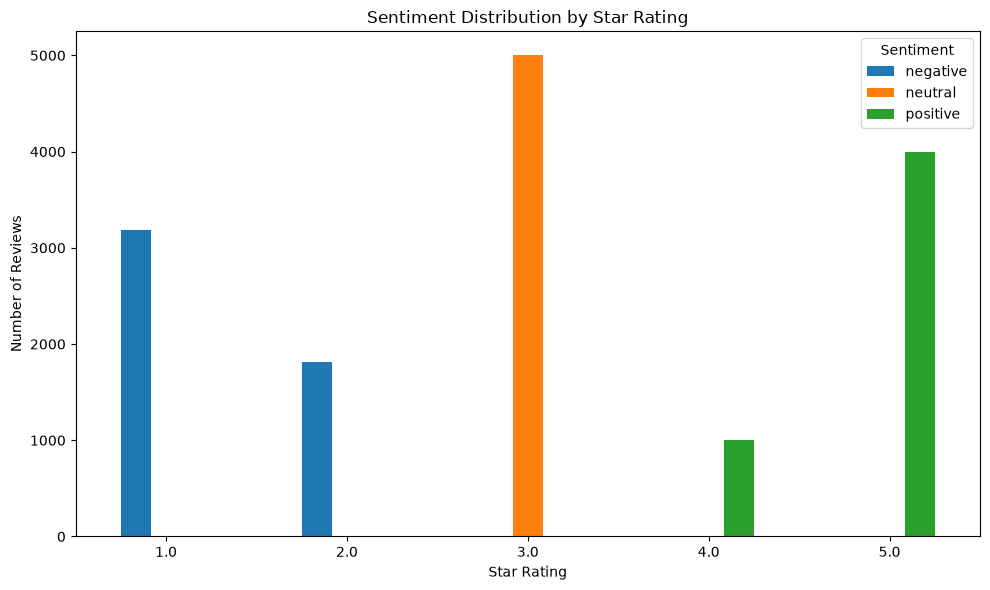

In [54]:
rating_counts.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [55]:
df["review_length"] = df["text_full"].str.len()

df.groupby("sentiment")["review_length"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
sentiment,,,,,
negative,5000,189.090400,135.0,19,8212
neutral,5000,217.518000,154.0,18,11352
positive,4999,187.366073,117.0,15,6451


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
negative_text